<a href="https://colab.research.google.com/github/ITERE001/House-prediction-model/blob/main/House_predictions_scikit_learn.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Ames House Price Prediction Pipeline
This notebook demonstrates a complete end-to-end Machine Learning pipeline to predict house prices using the Ames Housing Dataset. The pipeline covers exploratory data analysis notes, domain-specific missing value imputation, feature encoding, scaling, and comparative regression modeling (Linear Regression, Ridge, and Lasso).

In [19]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## 1. Data Acquisition and Exploration
First, we load the training dataset and inspect its structure to understand the features and check for initial data types.

In [20]:
path = "/content/train.csv"
data = pd.read_csv(path)
data.head()

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


## 2. Handling Missing Data
Real estate datasets often contain missing values that carry specific structural meanings.
* Many nominal categorical columns (like `PoolQC`, `Alley`, `Fence`) use `NaN` to indicate the **absence** of that amenity, rather than missing information.
* We replace these specific nulls with the category `'None'` to ensure the model retains this valuable information.
* For numeric values, we impute missing `MasVnrArea` with `0` and fallback missing `GarageYrBlt` to the year the house was built.

In [21]:
missing = data.isnull().sum()
missing[missing>0].sort_values(ascending=False)

,0
PoolQC,1453
MiscFeature,1406
Alley,1369
Fence,1179
MasVnrType,872
FireplaceQu,690
LotFrontage,259
GarageType,81
GarageYrBlt,81
GarageFinish,81


In [22]:
data.shape

(1460, 81)

In [23]:
none_cols = ['Alley', 'PoolQC', 'MiscFeature', 'Fence', 'FireplaceQu',
             'GarageType', 'GarageFinish', 'GarageQual', 'GarageCond',
             'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinType2']
data[none_cols] = data[none_cols].fillna('None')

data['MasVnrArea'] = data['MasVnrArea'].fillna(0)
data['GarageYrBlt'] = data['GarageYrBlt'].fillna(data['YearBuilt'])
data['Electrical'] = data['Electrical'].fillna(data['Electrical'].mode()[0])

print(data.isnull().sum().sum())   # should print 0

1131


### Neighborhood-Based Imputation
`LotFrontage` (linear feet of street connected to property) varies significantly by location. We impute the remaining missing values of `LotFrontage` using the median value of its respective `Neighborhood` to achieve higher accuracy.

In [24]:
data['MasVnrType'] = data['MasVnrType'].fillna('None')

data['LotFrontage'] = data.groupby('Neighborhood')['LotFrontage'].transform(
    lambda x: x.fillna(x.median())
)

print(data.isnull().sum().sum())   # should now print 0

0


## 3. Feature Engineering & Categorical Encoding
Before modeling, we must transform categorical features into numeric indicators:
* **Id Column Removal:** The unique identifier `Id` has no predictive power, so we drop it to prevent overfitting.
* **Numeric to Categorical Cast:** Features like `MSSubClass` (type of dwelling) and `MoSold` (month sold) are represented as integers but are fundamentally qualitative. We convert them to strings.
* **One-Hot Encoding:** We convert all categorical variables into dummy variables using `pd.get_dummies` to prepare them for linear models.

In [25]:
data = data.drop(columns=['Id'], errors='ignore')

# Numeric codes that are really categories
data['MSSubClass'] = data['MSSubClass'].astype(str)
data['MoSold'] = data['MoSold'].astype(str)

categorical_cols = data.select_dtypes(exclude=[np.number]).columns.to_list()
data1 = pd.get_dummies(data, columns=categorical_cols, drop_first=True, dtype=int)

print(data1.shape)

(1460, 283)


## 4. Dataset Partitioning & Target Scaling
* **Train-Test Split:** We split the dataset (80% train, 20% test) to validate our model's performance on unseen data.
* **Log Transformation:** House prices are typically right-skewed. By transforming `SalePrice` using `np.log1p()`, we make the target distribution more normal and stabilize variance, which satisfies fundamental assumptions of linear regression models.

In [26]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Lasso, Ridge
from sklearn.metrics import mean_squared_error, r2_score,mean_absolute_error
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV


In [27]:
X = data1.drop(columns=["SalePrice"])
y = np.log1p(data1["SalePrice"])
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
scaler = StandardScaler()


## 5. Model Training & Hyperparameter Tuning
We compare three linear modeling approaches: **Ridge Regression**, **Lasso Regression**, and **Ordinary Least Squares (OLS) Linear Regression**. All models utilize standard scaling to normalize feature magnitudes.

### Model A: Ridge Regression (L2 Regularization)
We use `GridSearchCV` to find the optimal L2 penalty (`alpha`) to control multicollinearity among our 282 features.

In [12]:
pipe = Pipeline([("scaler", scaler), ("model1", Ridge())])
param_grid = {"model1__alpha":np.logspace(-3, 3, 20)}
search = GridSearchCV(pipe, param_grid, cv=5, scoring='neg_mean_squared_error',n_jobs=-1)
search.fit(X_train, y_train)
print("Best parameters: ", search.best_params_)
print("Best cross-validation score: ", -search.best_score_)


Best parameters:  {'model1__alpha': np.float64(483.2930238571752)}
Best cross-validation score:  0.023935810370325907


In [13]:
ridge = Pipeline([("scaler", scaler), ("model1", Ridge(alpha=search.best_params_["model1__alpha"]))])
ridge.fit(X_train, y_train)
ridge_pred = ridge.predict(X_test)
print("Ridge Regression:----------------------------------------------------")
print("Mean Squared Error: ", mean_squared_error(y_test, ridge_pred))
print("Root Mean Squared Error: ", np.sqrt(mean_squared_error(y_test, ridge_pred)))
print("Mean Absolute Error: ", mean_absolute_error(y_test, ridge_pred))
print("R2 Score: ", r2_score(y_test, ridge_pred))
print("---------------------------------------------------------------------")

Ridge Regression:----------------------------------------------------
Mean Squared Error:  0.02396534934322702
Root Mean Squared Error:  0.15480745893924822
Mean Absolute Error:  0.09947068051668818
R2 Score:  0.8715758941934265
---------------------------------------------------------------------


### Model B: Lasso Regression (L1 Regularization & Feature Selection)
Lasso applies an L1 penalty that shrinks unimportant coefficients to exactly zero. We tune the regularization strength `alpha` across a logarithmic grid ranging from $10^{-4}$ to $10^{-1}$.

In [14]:
pipe1 = Pipeline([("scaler", StandardScaler()), ("model2", Lasso(max_iter=50000))])
param_grid1 = {"model2__alpha": np.logspace(-4, -1, 25)}   # 0.0001 to 0.1

search1 = GridSearchCV(pipe1, param_grid1, cv=5,
                       scoring="neg_mean_squared_error", n_jobs=-1)
search1.fit(X_train, y_train)

print("Best alpha:", search1.best_params_)
print("Best CV RMSE (log units):", np.sqrt(-search1.best_score_))

Best alpha: {'model2__alpha': np.float64(0.01)}
Best CV RMSE (log units): 0.16906472594189068


In [15]:
lasso = Pipeline([("scaler", scaler), ("model2", Lasso(alpha=search1.best_params_['model2__alpha'], max_iter=100000))])
lasso.fit(X_train, y_train)
lasso_pred = lasso.predict(X_test)
print("Lasso Regression:----------------------------------------------------")
print("Mean Squared Error: ", mean_squared_error(y_test, lasso_pred))
print("Root Mean Squared Error: ", np.sqrt(mean_squared_error(y_test, lasso_pred)))
print("Mean Absolute Error: ", mean_absolute_error(y_test, lasso_pred))
print("R2 Score: ", r2_score(y_test, lasso_pred))
print("---------------------------------------------------------------------")

Lasso Regression:----------------------------------------------------
Mean Squared Error:  0.022838809282003648
Root Mean Squared Error:  0.15112514443997613
Mean Absolute Error:  0.10153797586201499
R2 Score:  0.8776127308756667
---------------------------------------------------------------------


### Model C: Ordinary Least Squares (OLS) Linear Regression
We train a standard linear regression model without any regularization constraints to serve as our baseline performance metric.

In [16]:
lr = Pipeline([("scaler", scaler), ("model3", LinearRegression())])
lr.fit(X_train, y_train)
lr_pred = lr.predict(X_test)
print("Linear Regression:----------------------------------------------------")
print("Mean Squared Error: ", mean_squared_error(y_test, lr_pred))
print("Root Mean Squared Error: ", np.sqrt(mean_squared_error(y_test, lr_pred)))
print("Mean Absolute Error: ", mean_absolute_error(y_test, lr_pred))
print("R2 Score: ", r2_score(y_test, lr_pred))
print("---------------------------------------------------------------------")

Linear Regression:----------------------------------------------------
Mean Squared Error:  0.02918393161872539
Root Mean Squared Error:  0.17083305189197256
Mean Absolute Error:  0.0964871485130021
R2 Score:  0.8436108621502647
---------------------------------------------------------------------


## 6. Model Evaluation and Comparison
We evaluate the models on the test set using Root Mean Squared Error (RMSE), Mean Absolute Error (MAE), and $R^2$ Score to determine which method handles high-dimensional house data best.

In [17]:
print("------------------------------------------------------------------------------")
print("Ridge RMSE: ", np.sqrt(mean_squared_error(y_test, ridge_pred)))
print("Ridge mean absolute error: ", mean_absolute_error(y_test, ridge_pred))
print("Ridge R2 Score: ", r2_score(y_test, ridge_pred))
print("-------------------------------------------------------------------------------")
print("Lasso RMSE: ", np.sqrt(mean_squared_error(y_test, lasso_pred)))
print("Lasso mean absolute error: ", mean_absolute_error(y_test, lasso_pred))
print("Lasso R2 Score: ", r2_score(y_test, lasso_pred))
print("-------------------------------------------------------------------------------")
print("Linear Regression RMSE: ", np.sqrt(mean_squared_error(y_test, lr_pred)))
print("Linear Regression mean absolute error: ", mean_absolute_error(y_test, lr_pred))
print("Linear Regression R2 Score: ", r2_score(y_test, lr_pred))

------------------------------------------------------------------------------
Ridge RMSE:  0.15480745893924822
Ridge mean absolute error:  0.09947068051668818
Ridge R2 Score:  0.8715758941934265
-------------------------------------------------------------------------------
Lasso RMSE:  0.15112514443997613
Lasso mean absolute error:  0.10153797586201499
Lasso R2 Score:  0.8776127308756667
-------------------------------------------------------------------------------
Linear Regression RMSE:  0.17083305189197256
Linear Regression mean absolute error:  0.0964871485130021
Linear Regression R2 Score:  0.8436108621502647


In [18]:
coefs = pd.Series(search1.best_estimator_["model2"].coef_, index=X_train.columns)
print("Non-zero:", (coefs != 0).sum(), "of", len(coefs))
print(coefs[coefs != 0].sort_values(key=abs, ascending=False).head(10))

Non-zero: 57 of 282
GrLivArea       0.114792
OverallQual     0.105839
GarageCars      0.048796
YearBuilt       0.036918
OverallCond     0.028546
PoolQC_Gd      -0.023515
YearRemodAdd    0.021877
MSZoning_RM    -0.021435
BsmtFullBath    0.020713
CentralAir_Y    0.017749
dtype: float64


### Visualizing Model Coefficients
Let's visualize the top 10 positive and top 10 negative coefficients from the Lasso model to understand which features have the strongest impact on house price predictions.

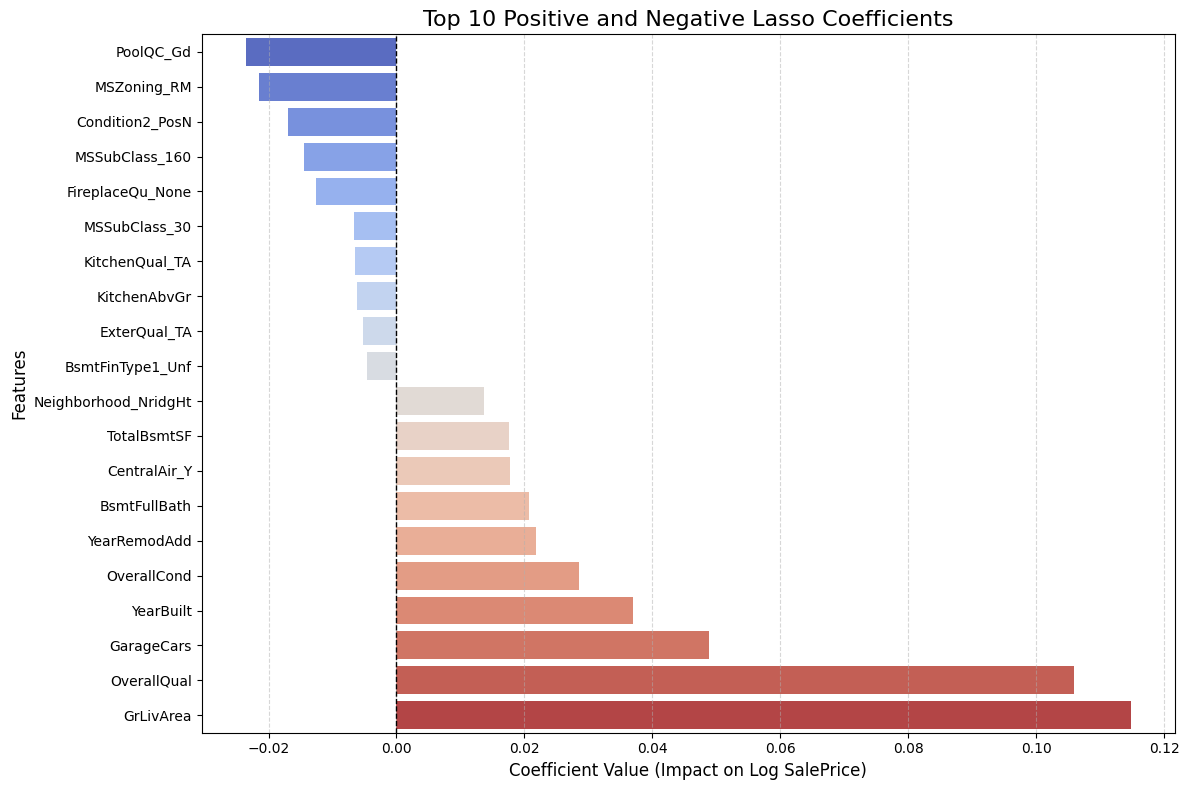

In [28]:
# Combine top 10 positive and top 10 negative coefficients
top_pos = coefs[coefs > 0].sort_values(ascending=False).head(10)
top_neg = coefs[coefs < 0].sort_values(ascending=True).head(10)
top_coefs = pd.concat([top_pos, top_neg]).sort_values()

# Plot the coefficients
plt.figure(figsize=(12, 8))
sns.barplot(x=top_coefs.values, y=top_coefs.index, hue=top_coefs.index, legend=False, palette='coolwarm')
plt.title('Top 10 Positive and Negative Lasso Coefficients', fontsize=16)
plt.xlabel('Coefficient Value (Impact on Log SalePrice)', fontsize=12)
plt.ylabel('Features', fontsize=12)
plt.axvline(0, color='black', linestyle='--', linewidth=1)
plt.grid(axis='x', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

## 7. Residual Analysis
To ensure our regression assumptions hold, we analyze the residuals (the differences between the actual log sale prices and predicted log sale prices) of our best model (Lasso).
* **Residuals vs. Fitted Plot**: Helps check for homoscedasticity (constant variance of errors) and non-linear patterns.
* **Distribution of Residuals**: Verifies whether the error terms are normally distributed.

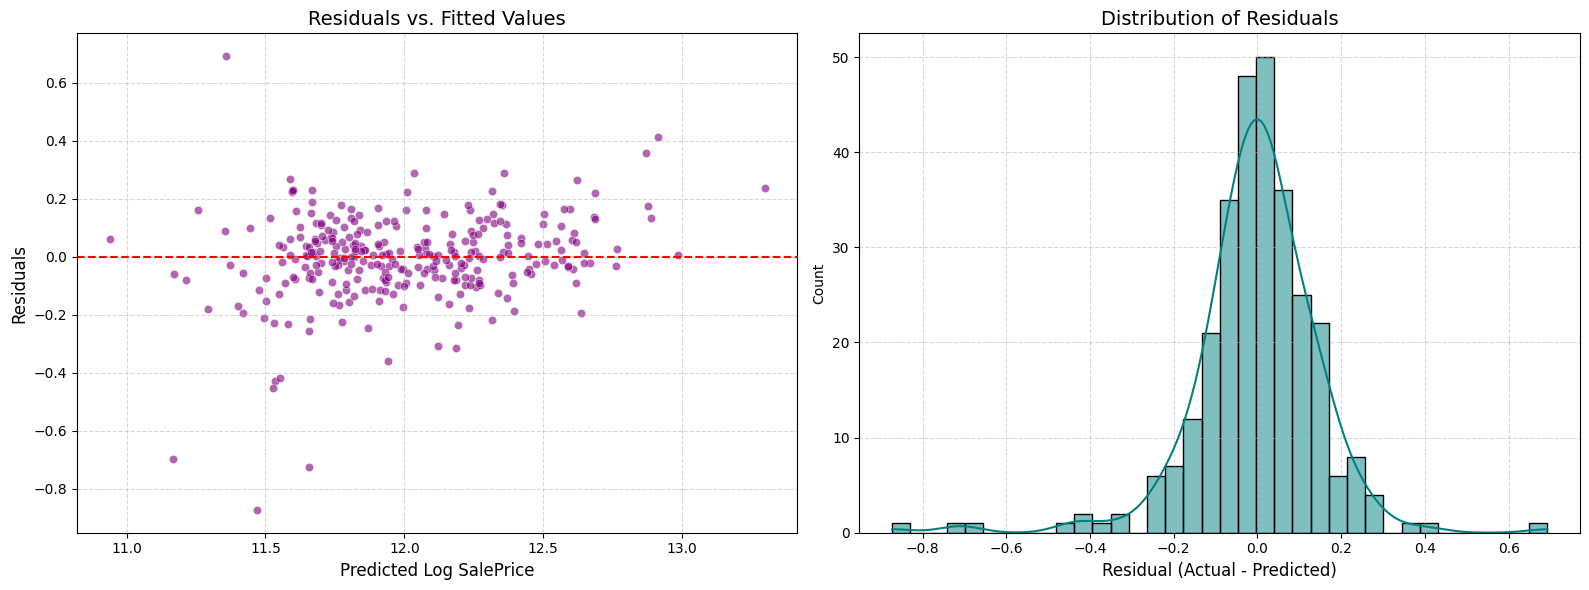

In [29]:
residuals = y_test - lasso_pred

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# 1. Residuals vs Fitted values
sns.scatterplot(x=lasso_pred, y=residuals, ax=axes[0], alpha=0.6, color='purple')
axes[0].axhline(0, color='red', linestyle='--', linewidth=1.5)
axes[0].set_title('Residuals vs. Fitted Values', fontsize=14)
axes[0].set_xlabel('Predicted Log SalePrice', fontsize=12)
axes[0].set_ylabel('Residuals', fontsize=12)
axes[0].grid(True, linestyle='--', alpha=0.5)

# 2. Histogram of Residuals
sns.histplot(residuals, kde=True, ax=axes[1], color='teal')
axes[1].set_title('Distribution of Residuals', fontsize=14)
axes[1].set_xlabel('Residual (Actual - Predicted)', fontsize=12)
axes[1].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

### Predicted vs. Actual Values Plot
To visually evaluate the model accuracy, we plot the predicted log sale prices against the actual log sale prices. The closer the points are to the diagonal dashed line (where predicted equals actual), the more accurate our predictions are.

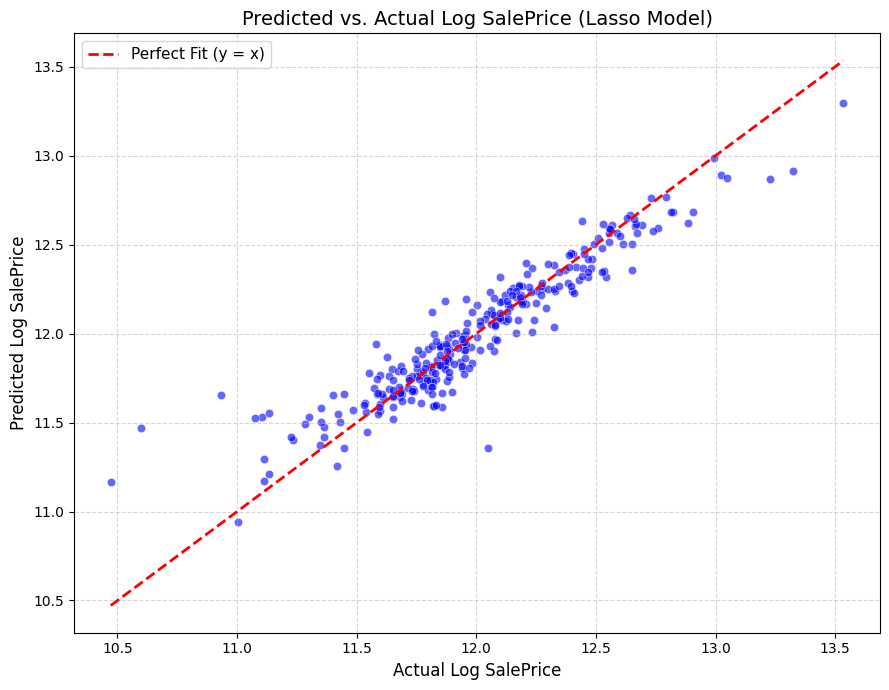

In [30]:
plt.figure(figsize=(9, 7))
sns.scatterplot(x=y_test, y=lasso_pred, alpha=0.6, color='blue', edgecolor='w')

# Plot a diagonal reference line representing perfect prediction
min_val = min(y_test.min(), lasso_pred.min())
max_val = max(y_test.max(), lasso_pred.max())
plt.plot([min_val, max_val], [min_val, max_val], color='red', linestyle='--', linewidth=2, label='Perfect Fit (y = x)')

plt.title('Predicted vs. Actual Log SalePrice (Lasso Model)', fontsize=14)
plt.xlabel('Actual Log SalePrice', fontsize=12)
plt.ylabel('Predicted Log SalePrice', fontsize=12)
plt.legend(fontsize=11)
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()